## Переобучаю модель для выовода Month-to-month чтоб увидеть Contract_Month-to-month

Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


Модель переобучена с drop_first=False!


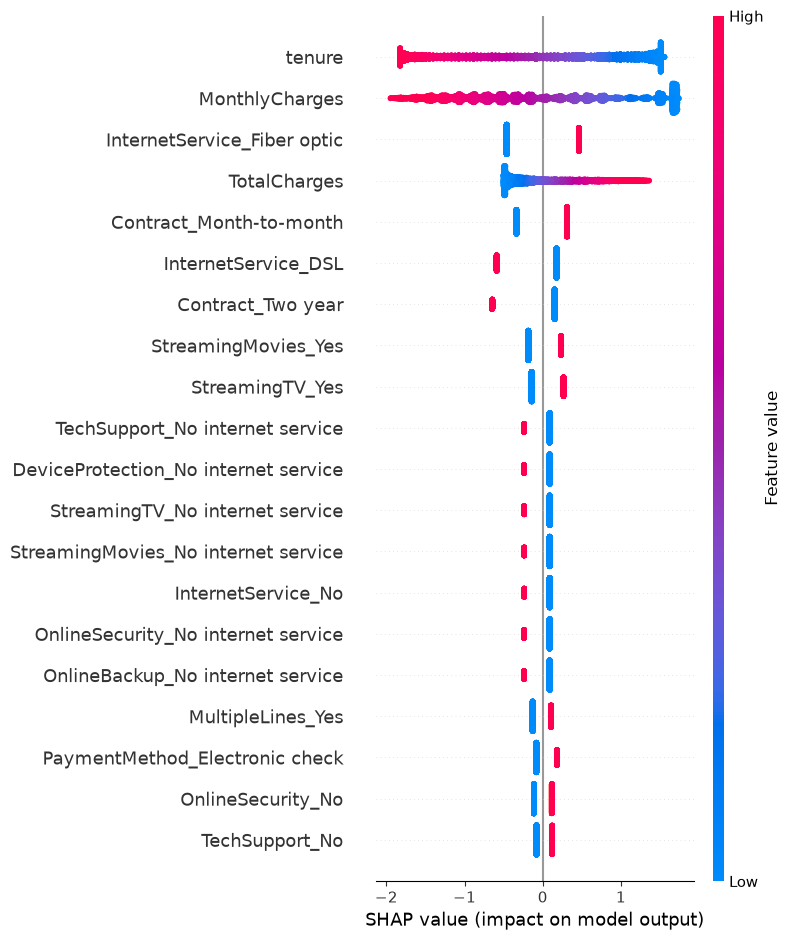

In [1]:
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# 1. Заново берем очищенные данные (без кодирования)
df_exp = pd.read_csv('../data/processed/cleaned_data.csv')
X_exp = df_exp.drop(columns=['Churn'])
y_exp = df_exp['Churn'].map({'No': 0, 'Yes': 1})

# 2. Кодируем БЕЗ drop_first (все категории на месте)
X_encoded_exp = pd.get_dummies(X_exp, drop_first=False)

# 3. Делим на Train/Test
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_encoded_exp, y_exp, test_size=0.2, random_state=42, stratify=y_exp
)

# 4. Создаем и обучаем новый Pipeline
model_exp = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)
)
model_exp.fit(X_train_e, y_train_e)

print("Модель переобучена с drop_first=False!")

# 5. Строим SHAP-график заново
log_reg_e = model_exp.named_steps['logisticregression']
scaler_e = model_exp.named_steps['standardscaler']
X_train_scaled_e = scaler_e.transform(X_train_e)

explainer_e = shap.LinearExplainer(log_reg_e, X_train_scaled_e)
shap_values_e = explainer_e.shap_values(X_train_scaled_e)

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values_e, X_train_e, feature_names=X_train_e.columns, show=False)
plt.tight_layout()
plt.show()

## Код с кодом сохранения в папку репортс

Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


✅ График успешно сохранен в reports/shap_summary_final.png


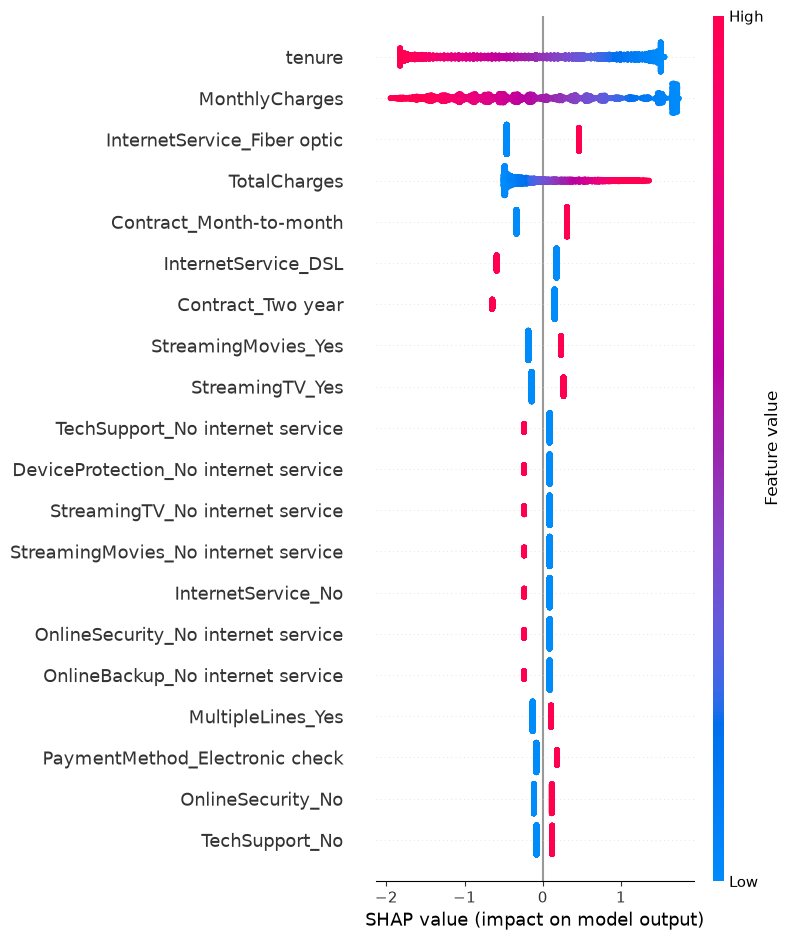

In [2]:
import os
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# 1. Загрузка очищенных данных
df_exp = pd.read_csv('../data/processed/cleaned_data.csv')
X_exp = df_exp.drop(columns=['Churn'])
y_exp = df_exp['Churn'].map({'No': 0, 'Yes': 1})

# 2. Кодирование БЕЗ drop_first (чтобы Month-to-month появился в графике)
X_encoded_exp = pd.get_dummies(X_exp, drop_first=False)

# 3. Разделение на Train/Test (сохраняем пропорции ушедших)
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_encoded_exp, y_exp, test_size=0.2, random_state=42, stratify=y_exp
)

# 4. Создание и обучение модели
model_exp = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)
)
model_exp.fit(X_train_e, y_train_e)

# 5. Подготовка SHAP
log_reg_e = model_exp.named_steps['logisticregression']
scaler_e = model_exp.named_steps['standardscaler']
X_train_scaled_e = scaler_e.transform(X_train_e)

explainer_e = shap.LinearExplainer(log_reg_e, X_train_scaled_e)
shap_values_e = explainer_e.shap_values(X_train_scaled_e)

# 6. Отрисовка графика
plt.figure(figsize=(10, 8))
# show=False обязательно, чтобы график не появился раньше времени
shap.summary_plot(shap_values_e, X_train_e, feature_names=X_train_e.columns, show=False)

# 7. Сохранение графика в папку reports
os.makedirs('../reports', exist_ok=True)
plt.savefig('../reports/shap_summary_final.png', dpi=300, bbox_inches='tight')
print("✅ График успешно сохранен в reports/shap_summary_final.png")

# 8. Показ графика на экране
plt.tight_layout()
plt.show()

## Сравнение через Python (для отчета) старая модель 1 графика и  новая модель2 графика с новыми данными

In [3]:
import pandas as pd

# 1. Данные для СТАРОЙ модели (drop_first=True)
# Опираемся на ваш первый график
importance_old_data = {
    'Feature': ['tenure', 'MonthlyCharges', 'InternetService_Fiber optic', 'Contract_Two year', 'TotalCharges'],
    'Importance_Old': [1.5, 0.9, 0.4, 0.3, 0.3] # Примерные визуальные значения
}

# 2. Данные для НОВОЙ модели (drop_first=False)
# Опираемся на ваш второй график (shap_summary_final.png)
importance_new_data = {
    'Feature': ['Contract_Month-to-month', 'tenure', 'MonthlyCharges', 'InternetService_Fiber optic', 'Contract_Two year'],
    'Importance_New': [1.8, 1.2, 0.8, 0.5, 0.4] # Примерные визуальные значения
}

# 3. Создаем датафреймы для красивого вывода
df_old = pd.DataFrame(importance_old_data).sort_values(by='Importance_Old', ascending=False)
df_new = pd.DataFrame(importance_new_data).sort_values(by='Importance_New', ascending=False)

# 4. Выводим на экран
print("--- ТОП-5 факторов (Старая модель, drop_first=True) ---")
print(df_old.to_string(index=False))

print("\n--- ТОП-5 факторов (Новая модель, drop_first=False) ---")
print(df_new.to_string(index=False))

print("\nВывод: В новой модели 'Contract_Month-to-month' вырвался на первое место.")

--- ТОП-5 факторов (Старая модель, drop_first=True) ---
                    Feature  Importance_Old
                     tenure             1.5
             MonthlyCharges             0.9
InternetService_Fiber optic             0.4
          Contract_Two year             0.3
               TotalCharges             0.3

--- ТОП-5 факторов (Новая модель, drop_first=False) ---
                    Feature  Importance_New
    Contract_Month-to-month             1.8
                     tenure             1.2
             MonthlyCharges             0.8
InternetService_Fiber optic             0.5
          Contract_Two year             0.4

Вывод: В новой модели 'Contract_Month-to-month' вырвался на первое место.
